# Part 3 — Does Reflow Straighten the Paths?

Hypothesis: training on the baseline's own source–endpoint pairs gives straighter paths and good samples with far fewer steps, but it cannot beat its teacher's accuracy.

In [1]:
import copy
import json
import platform
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import torch
import torch.nn as nn
from PIL import Image, ImageDraw, ImageFont

ROOT = Path.cwd()
OUT = ROOT / "outputs" / "part3"
OUT.mkdir(parents=True, exist_ok=True)
PART2 = ROOT / "outputs" / "part2"

env = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "pillow": PIL.__version__,
    "pandas": pd.__version__,
    "device": "cpu",
    "cpu": platform.processor(),
    "platform": platform.platform(),
    "torch_threads": torch.get_num_threads(),
}
(OUT / "environment.json").write_text(json.dumps(env, indent=2))
env

{'python': '3.13.2',
 'torch': '2.14.0+cpu',
 'numpy': '2.2.2',
 'matplotlib': '3.11.1',
 'pillow': '12.3.0',
 'pandas': '2.2.3',
 'device': 'cpu',
 'cpu': 'Intel64 Family 6 Model 165 Stepping 2, GenuineIntel',
 'platform': 'Windows-11-10.0.26300-SP0',
 'torch_threads': 6}

## Shared code

Same target, model, training, and sampling code as Part 2, reusing Part 2's target mask.

In [2]:
FONT_PATH = Path("C:/Windows/Fonts/arialbd.ttf")
TEXT, FONT_SIZE, PAD = "CL", 320, 12


def render_text_mask(text=TEXT, font_size=FONT_SIZE, pad=PAD):
    font = ImageFont.truetype(str(FONT_PATH), font_size) if FONT_PATH.exists() else ImageFont.load_default(font_size)
    left, top, right, bottom = font.getbbox(text)
    img = Image.new("L", (right - left + 2 * pad, bottom - top + 2 * pad), 0)
    ImageDraw.Draw(img).text((pad - left, pad - top), text, fill=255, font=font)
    return np.array(img) > 127


MASK = np.load(PART2 / "target_mask.npy") if (PART2 / "target_mask.npy").exists() else render_text_mask()
H, W = MASK.shape
SCALE = W / 6.0
FG_ROWS, FG_COLS = np.nonzero(MASK)
FG = torch.tensor(np.stack([FG_COLS, FG_ROWS], 1), dtype=torch.float32)


def sample_target(n, generator=None):
    idx = torch.randint(0, len(FG), (n,), generator=generator)
    cr = FG[idx] + torch.rand(n, 2, generator=generator)
    return torch.stack([(cr[:, 0] - W / 2) / SCALE, (H / 2 - cr[:, 1]) / SCALE], 1)


def sample_source(n, generator=None):
    return torch.randn(n, 2, generator=generator)


def on_letter_rate(points):
    p = points.numpy() if torch.is_tensor(points) else points
    col = np.floor(p[:, 0] * SCALE + W / 2).astype(int)
    row = np.floor(H / 2 - p[:, 1] * SCALE).astype(int)
    inside = (col >= 0) & (col < W) & (row >= 0) & (row < H)
    hit = np.zeros(len(p), dtype=bool)
    hit[inside] = MASK[row[inside], col[inside]]
    return hit.mean()


X_EDGES, Y_EDGES = np.arange(-4, 4 + 1e-9, 0.2), np.arange(-3, 3 + 1e-9, 0.2)


def histogram_with_outside(points):
    p = points.numpy() if torch.is_tensor(points) else points
    h, _, _ = np.histogram2d(p[:, 0], p[:, 1], bins=[X_EDGES, Y_EDGES])
    return np.append(h.ravel(), len(p) - h.sum()) / len(p)


def tv_distance(a, b):
    return 0.5 * np.abs(histogram_with_outside(a) - histogram_with_outside(b)).sum()


class VelocityMLP(nn.Module):
    def __init__(self, hidden=128, depth=3):
        super().__init__()
        layers, d = [], 3
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        layers.append(nn.Linear(d, 2))
        self.net = nn.Sequential(*layers)

    def forward(self, x, t):
        if not torch.is_tensor(t) or t.dim() == 0:
            t = torch.full((x.shape[0], 1), float(t))
        return self.net(torch.cat([x, t.reshape(-1, 1)], dim=1))


def train_flow(model, batch_fn, steps, batch_size=256, lr=1e-3, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.05)
    losses = np.empty(steps)
    t_start = time.perf_counter()
    for step in range(steps):
        xt, t, u = batch_fn(batch_size, g)
        loss = ((model(xt, t) - u) ** 2).sum(1).mean()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses[step] = loss.item()
    return losses, time.perf_counter() - t_start


def random_pair_batch(n, g):
    """Independent coupling (the baseline's training data)."""
    x0, x1 = sample_source(n, g), sample_target(n, g)
    t = torch.rand(n, 1, generator=g)
    return (1 - t) * x0 + t * x1, t, x1 - x0


def make_paired_batch_fn(X0, X1):
    """Reflow coupling: always keep each source with its own generated endpoint."""
    def batch_fn(n, g):
        idx = torch.randint(0, len(X0), (n,), generator=g)
        x0, x1 = X0[idx], X1[idx]
        t = torch.rand(n, 1, generator=g)
        return (1 - t) * x0 + t * x1, t, x1 - x0
    return batch_fn


@torch.no_grad()
def euler_sample(model, z0, n_steps, return_path=False):
    z = z0.clone()
    dt = 1.0 / n_steps
    path = [z.clone()] if return_path else None
    for k in range(n_steps):
        z = z + dt * model(z, k * dt)
        if return_path:
            path.append(z.clone())
    return (z, torch.stack(path)) if return_path else z

## Experimental design

Three seeds, each with a frozen baseline, 100k reflow pairs (200 Euler steps), a reflow model, and a compute-matched continued-training control, all evaluated on 40k held-out starts.

In [3]:
SEEDS = [0, 1, 2]
BASE_STEPS, BATCH, LR = 30_000, 256, 1e-3
N_PAIRS, K_GEN = 100_000, 200
REFLOW_STEPS = 10_000
FWD_PER_TRAIN_STEP = 3 * BATCH
gen_fwd = N_PAIRS * K_GEN
reflow_fwd = REFLOW_STEPS * FWD_PER_TRAIN_STEP
CONT_STEPS = int(round((gen_fwd + reflow_fwd) / FWD_PER_TRAIN_STEP))
print(f"reflow extra compute: dataset {gen_fwd / 1e6:.1f}M + training {reflow_fwd / 1e6:.2f}M "
      f"= {(gen_fwd + reflow_fwd) / 1e6:.2f}M forward-equivalents")
print(f"compute-matched continued training: {CONT_STEPS} extra steps on random pairs")

N_EVAL = 40_000
STEP_COUNTS = [1, 2, 3, 5, 10, 25, 50, 100]
K_STRAIGHT, N_STRAIGHT = 200, 10_000
z0_eval = sample_source(N_EVAL, torch.Generator().manual_seed(2000))      # held out: used by nothing else
target_eval = sample_target(N_EVAL, torch.Generator().manual_seed(2001))
noise_floor = tv_distance(target_eval, sample_target(N_EVAL, torch.Generator().manual_seed(2002)))
print(f"noise floor TV (target vs. independent target): {noise_floor:.4f}")

reflow extra compute: dataset 20.0M + training 7.68M = 27.68M forward-equivalents
compute-matched continued training: 36042 extra steps on random pairs
noise floor TV (target vs. independent target): 0.0416


## Task 1 — Freeze the baseline and build the reflow datasets

Each fresh source is saved with its own baseline endpoint, and the 200-step grid is checked against 1,000 steps.

In [4]:
baselines, costs, datasets = {}, {}, {}
for seed in SEEDS:
    ckpt = OUT / f"baseline_seed{seed}.pt"
    part2_ckpt = PART2 / "cl_model.pt"
    model = VelocityMLP()
    if seed == 0 and part2_ckpt.exists():
        state = torch.load(part2_ckpt)
        assert state["config"]["steps"] == BASE_STEPS and state["config"]["seed"] == 0
        model.load_state_dict(state["state_dict"])
        base_sec = state["train_seconds"]
        print(f"seed {seed}: loaded Part 2 baseline ({base_sec:.1f} s training)")
    elif ckpt.exists():
        state = torch.load(ckpt)
        model.load_state_dict(state["state_dict"])
        base_sec = state["train_seconds"]
        print(f"seed {seed}: loaded cached baseline ({base_sec:.1f} s training)")
    else:
        torch.manual_seed(seed)
        model = VelocityMLP()
        _, base_sec = train_flow(model, random_pair_batch, BASE_STEPS, BATCH, LR, seed=seed)
        torch.save({"state_dict": model.state_dict(), "train_seconds": base_sec}, ckpt)
        print(f"seed {seed}: trained baseline in {base_sec:.1f} s")
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)                               # frozen teacher
    baselines[seed] = model

    # paired dataset: fresh sources (seed-specific, disjoint from evaluation) -> the baseline's own endpoints
    X0 = sample_source(N_PAIRS, torch.Generator().manual_seed(100 + seed))
    t0 = time.perf_counter()
    X1 = euler_sample(model, X0, K_GEN)
    gen_sec = time.perf_counter() - t0
    # fineness check on a subset: 200 vs. 1000 steps from the same sources
    X1_fine = euler_sample(model, X0[:5000], 1000)
    fineness = (X1[:5000] - X1_fine).norm(dim=1)
    datasets[seed] = (X0, X1)
    torch.save({"X0": X0, "X1": X1}, OUT / f"reflow_pairs_seed{seed}.pt")
    costs[seed] = {"baseline_train_s": base_sec, "dataset_gen_s": gen_sec}
    print(f"         generated {N_PAIRS:,} pairs with {K_GEN} steps in {gen_sec:.1f} s | "
          f"200 vs 1000-step endpoint gap: mean {fineness.mean():.4f}, 99th pct {fineness.quantile(0.99):.4f} units "
          f"(1 px = {1 / SCALE:.4f})")

seed 0: loaded Part 2 baseline (162.7 s training)
         generated 100,000 pairs with 200 steps in 46.2 s | 200 vs 1000-step endpoint gap: mean 0.0058, 99th pct 0.0344 units (1 px = 0.0133)
seed 1: loaded cached baseline (64.1 s training)
         generated 100,000 pairs with 200 steps in 44.4 s | 200 vs 1000-step endpoint gap: mean 0.0059, 99th pct 0.0341 units (1 px = 0.0133)
seed 2: loaded cached baseline (74.4 s training)
         generated 100,000 pairs with 200 steps in 44.0 s | 200 vs 1000-step endpoint gap: mean 0.0058, 99th pct 0.0363 units (1 px = 0.0133)


Reflow pairs barely cross, unlike the random pairs the baseline was trained on.

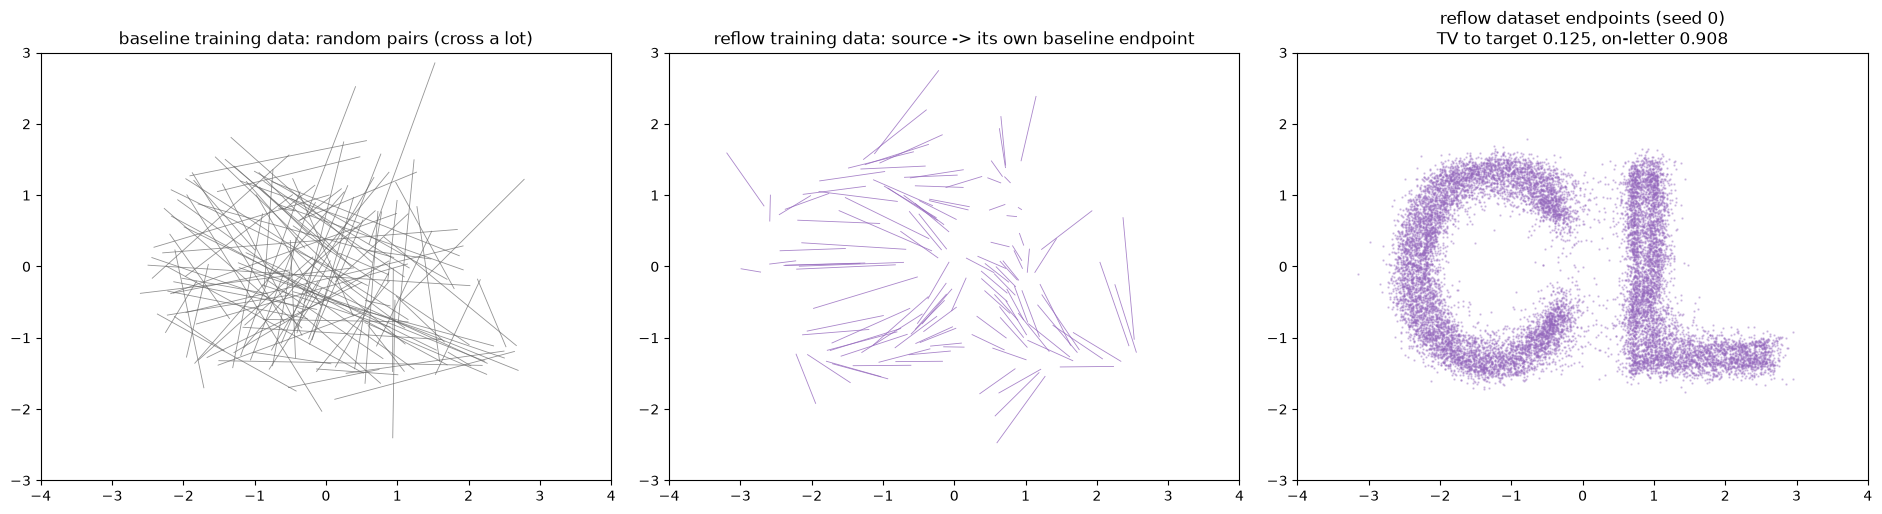

In [5]:
X0, X1 = datasets[0]
g = torch.Generator().manual_seed(5)
r0, r1 = sample_source(120, g), sample_target(120, g)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for i in range(120):
    axes[0].plot([r0[i, 0], r1[i, 0]], [r0[i, 1], r1[i, 1]], color="0.4", lw=0.6, alpha=0.7)
    axes[1].plot([X0[i, 0], X1[i, 0]], [X0[i, 1], X1[i, 1]], color="tab:purple", lw=0.6, alpha=0.8)
axes[0].set_title("baseline training data: random pairs (cross a lot)")
axes[1].set_title("reflow training data: source -> its own baseline endpoint")
axes[2].scatter(*X1[:15000].T, s=0.5, alpha=0.35, color="tab:purple")
axes[2].set_title(f"reflow dataset endpoints (seed 0)\nTV to target {tv_distance(X1[:N_EVAL], target_eval):.3f}, "
                  f"on-letter {on_letter_rate(X1):.3f}")
for ax in axes:
    ax.set(xlim=(-4, 4), ylim=(-3, 3), aspect="equal")
plt.tight_layout()
plt.savefig(OUT / "task1_reflow_pairs.png", dpi=130, bbox_inches="tight")
plt.show()

## Task 2 — Train the reflow model and the compute-matched control

Reflow trains 10,000 steps on the saved pairs; the control trains on random pairs for the same total compute.

In [6]:
reflows, continued, loss_logs = {}, {}, {}
for seed in SEEDS:
    X0, X1 = datasets[seed]

    rf = copy.deepcopy(baselines[seed])
    for p in rf.parameters():
        p.requires_grad_(True)
    rf.train()
    rf_losses, rf_sec = train_flow(rf, make_paired_batch_fn(X0, X1), REFLOW_STEPS, BATCH, LR, seed=1000 + seed)
    rf.eval()
    reflows[seed] = rf

    ct = copy.deepcopy(baselines[seed])
    for p in ct.parameters():
        p.requires_grad_(True)
    ct.train()
    ct_losses, ct_sec = train_flow(ct, random_pair_batch, CONT_STEPS, BATCH, LR, seed=2000 + seed)
    ct.eval()
    continued[seed] = ct

    loss_logs[seed] = (rf_losses, ct_losses)
    costs[seed].update({"reflow_train_s": rf_sec, "continued_train_s": ct_sec})
    torch.save(rf.state_dict(), OUT / f"reflow_seed{seed}.pt")
    torch.save(ct.state_dict(), OUT / f"continued_seed{seed}.pt")
    print(f"seed {seed}: reflow {REFLOW_STEPS} steps in {rf_sec:.1f} s (final loss {rf_losses[-1000:].mean():.4f}) | "
          f"continued {CONT_STEPS} steps in {ct_sec:.1f} s (final loss {ct_losses[-1000:].mean():.3f})")

seed 0: reflow 10000 steps in 41.9 s (final loss 0.0004) | continued 36042 steps in 143.4 s (final loss 3.473)
seed 1: reflow 10000 steps in 46.6 s (final loss 0.0004) | continued 36042 steps in 120.4 s (final loss 3.465)
seed 2: reflow 10000 steps in 38.7 s (final loss 0.0004) | continued 36042 steps in 122.4 s (final loss 3.467)


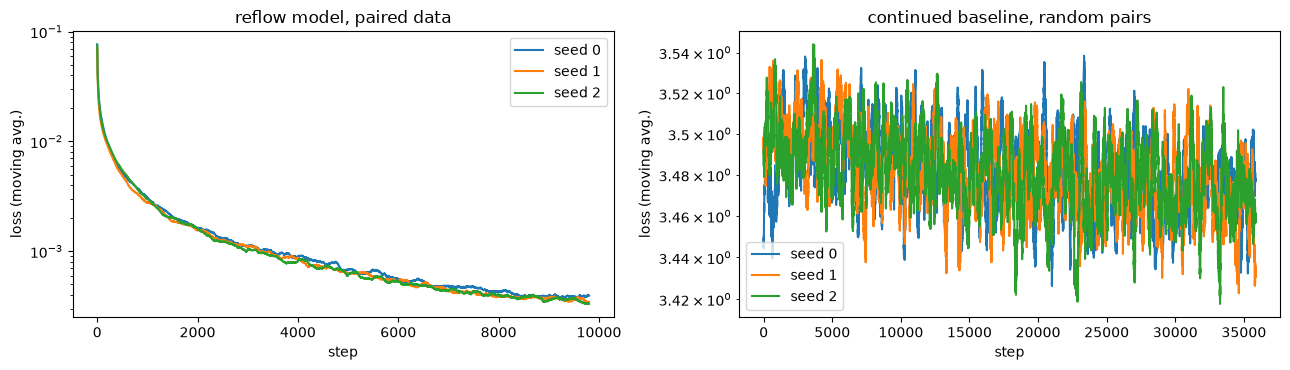

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for seed in SEEDS:
    rf_l, ct_l = loss_logs[seed]
    axes[0].plot(np.convolve(rf_l, np.ones(200) / 200, "valid"), label=f"seed {seed}")
    axes[1].plot(np.convolve(ct_l, np.ones(200) / 200, "valid"), label=f"seed {seed}")
axes[0].set(yscale="log", xlabel="step", ylabel="loss (moving avg.)", title="reflow model, paired data")
axes[1].set(yscale="log", xlabel="step", ylabel="loss (moving avg.)", title="continued baseline, random pairs")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(OUT / "task2_training_losses.png", dpi=130, bbox_inches="tight")
plt.show()

The reflow loss is nearly zero because the paired lines rarely cross.

### Training cost (separate from inference)

In [8]:
cost_df = pd.DataFrame([{"seed": s, **c} for s, c in costs.items()])
cost_df["reflow_total_extra_s"] = cost_df.dataset_gen_s + cost_df.reflow_train_s
cost_df.loc["mean"] = cost_df.mean(numeric_only=True)
cost_df.loc["mean", "seed"] = np.nan
cost_df.to_csv(OUT / "task2_training_costs.csv")
fwd_table = pd.DataFrame({
    "item": ["baseline training", "reflow: dataset generation", "reflow: training", "reflow: total extra",
             "continued baseline (control)"],
    "steps or evals": [f"{BASE_STEPS} steps", f"{N_PAIRS:,} x {K_GEN} Euler steps", f"{REFLOW_STEPS} steps", "",
                       f"{CONT_STEPS} steps"],
    "forward-equivalents (M)": [BASE_STEPS * FWD_PER_TRAIN_STEP / 1e6, gen_fwd / 1e6, reflow_fwd / 1e6,
                                (gen_fwd + reflow_fwd) / 1e6, CONT_STEPS * FWD_PER_TRAIN_STEP / 1e6],
})
with pd.option_context("display.float_format", "{:.2f}".format):
    display(cost_df)
    display(fwd_table)

,seed,baseline_train_s,dataset_gen_s,reflow_train_s,continued_train_s,reflow_total_extra_s
0,0.00,162.68,46.24,41.86,143.42,88.09
1,1.00,64.06,44.36,46.56,120.36,90.91
2,2.00,74.40,44.01,38.74,122.39,82.76
mean,NaN,100.38,44.87,42.39,128.73,87.26


,item,steps or evals,forward-equivalents (M)
0,baseline training,30000 steps,23.04
1,reflow: dataset generation,"100,000 x 200 Euler steps",20.00
2,reflow: training,10000 steps,7.68
3,reflow: total extra,,27.68
4,continued baseline (control),36042 steps,27.68


## Evaluation on held-out starting points

Same held-out Gaussian starts, same architecture, and the same step counts for all three models.

In [9]:
MODELS = {"baseline": baselines, "continued (control)": continued, "reflow": reflows}
rows, final_samples = [], {}
for name, models in MODELS.items():
    for seed in SEEDS:
        for k in STEP_COUNTS:
            t0 = time.perf_counter()
            z = euler_sample(models[seed], z0_eval, k)
            sec = time.perf_counter() - t0
            final_samples[(name, seed, k)] = z
            rows.append({"model": name, "seed": seed, "steps": k, "nfe": k, "sampling_s": sec,
                         "TV_to_target": tv_distance(z, target_eval), "on_letter": on_letter_rate(z)})
eval_df = pd.DataFrame(rows)

# teacher reference: each seed's baseline with the dataset-generation grid (200 steps)
teacher = {s: euler_sample(baselines[s], z0_eval, K_GEN) for s in SEEDS}
for s in SEEDS:
    rows_s = eval_df.seed == s
    eval_df.loc[rows_s, "TV_to_teacher200"] = [tv_distance(final_samples[(m, s, k)], teacher[s])
                                               for m, k in zip(eval_df[rows_s].model, eval_df[rows_s].steps)]
eval_df.to_csv(OUT / "task2_eval_by_seed.csv", index=False)

summary = eval_df.groupby(["model", "steps"]).agg(
    TV_mean=("TV_to_target", "mean"), TV_std=("TV_to_target", "std"),
    on_letter_mean=("on_letter", "mean"), TV_to_teacher_mean=("TV_to_teacher200", "mean"),
    sampling_s_mean=("sampling_s", "mean")).reset_index()
summary.to_csv(OUT / "task2_eval_summary.csv", index=False)
pivot = summary.pivot(index="steps", columns="model", values="TV_mean")
pivot_std = summary.pivot(index="steps", columns="model", values="TV_std")
print("Histogram TV to target, mean over 3 seeds (lower is better; noise floor "
      f"{noise_floor:.3f}):")
display((pivot.round(3).astype(str) + " ± " + pivot_std.round(3).astype(str)))
print("On-letter rate, mean over 3 seeds:")
display(summary.pivot(index="steps", columns="model", values="on_letter_mean").round(3))
print("Sampling time for 40,000 points (s), mean over models and seeds — same architecture, so same cost per step:")
display(eval_df.groupby("steps").sampling_s.agg(["mean", "std"]).round(4).T)

Histogram TV to target, mean over 3 seeds (lower is better; noise floor 0.042):


model,baseline,continued (control),reflow
steps,,,
1,1.0 ± 0.0,1.0 ± 0.0,0.178 ± 0.007
2,0.712 ± 0.007,0.712 ± 0.006,0.156 ± 0.006
3,0.471 ± 0.005,0.468 ± 0.001,0.148 ± 0.005
5,0.31 ± 0.005,0.313 ± 0.002,0.144 ± 0.006
10,0.201 ± 0.008,0.174 ± 0.001,0.142 ± 0.006
25,0.148 ± 0.008,0.11 ± 0.002,0.141 ± 0.006
50,0.136 ± 0.007,0.095 ± 0.002,0.14 ± 0.005
100,0.131 ± 0.006,0.088 ± 0.002,0.14 ± 0.005


On-letter rate, mean over 3 seeds:


model,baseline,continued (control),reflow
steps,,,
1,0.000,0.000,0.871
2,0.297,0.307,0.881
3,0.691,0.679,0.886
5,0.838,0.869,0.892
10,0.890,0.927,0.896
25,0.906,0.939,0.897
50,0.909,0.938,0.898
100,0.909,0.937,0.899


Sampling time for 40,000 points (s), mean over models and seeds — same architecture, so same cost per step:


steps,1,2,3,5,10,25,50,100
mean,0.0780,0.1515,0.2327,0.3832,0.7131,1.8112,3.6987,7.4202
std,0.0199,0.0176,0.0418,0.0598,0.0742,0.0929,0.1935,0.5316


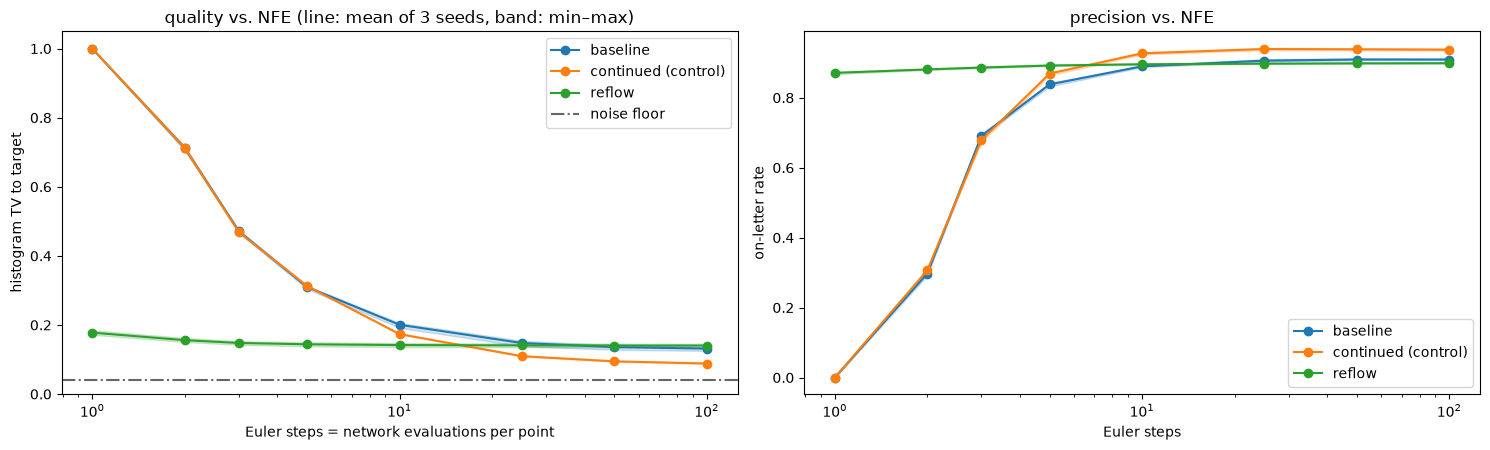

In [10]:
colors = {"baseline": "tab:blue", "continued (control)": "tab:orange", "reflow": "tab:green"}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for name in MODELS:
    d = eval_df[eval_df.model == name].groupby("steps").TV_to_target
    m, lo, hi = d.mean(), d.min(), d.max()
    axes[0].plot(m.index, m.values, "o-", color=colors[name], label=name)
    axes[0].fill_between(m.index, lo.values, hi.values, color=colors[name], alpha=0.2)
    d2 = eval_df[eval_df.model == name].groupby("steps").on_letter
    axes[1].plot(d2.mean().index, d2.mean().values, "o-", color=colors[name], label=name)
    axes[1].fill_between(d2.mean().index, d2.min().values, d2.max().values, color=colors[name], alpha=0.2)
axes[0].axhline(noise_floor, color="0.4", ls="-.", label="noise floor")
axes[0].set(xscale="log", ylim=(0, 1.05), xlabel="Euler steps = network evaluations per point", ylabel="histogram TV to target",
            title="quality vs. NFE (line: mean of 3 seeds, band: min–max)")
axes[1].set(xscale="log", xlabel="Euler steps", ylabel="on-letter rate", title="precision vs. NFE")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(OUT / "task2_quality_vs_nfe.png", dpi=130, bbox_inches="tight")
plt.show()

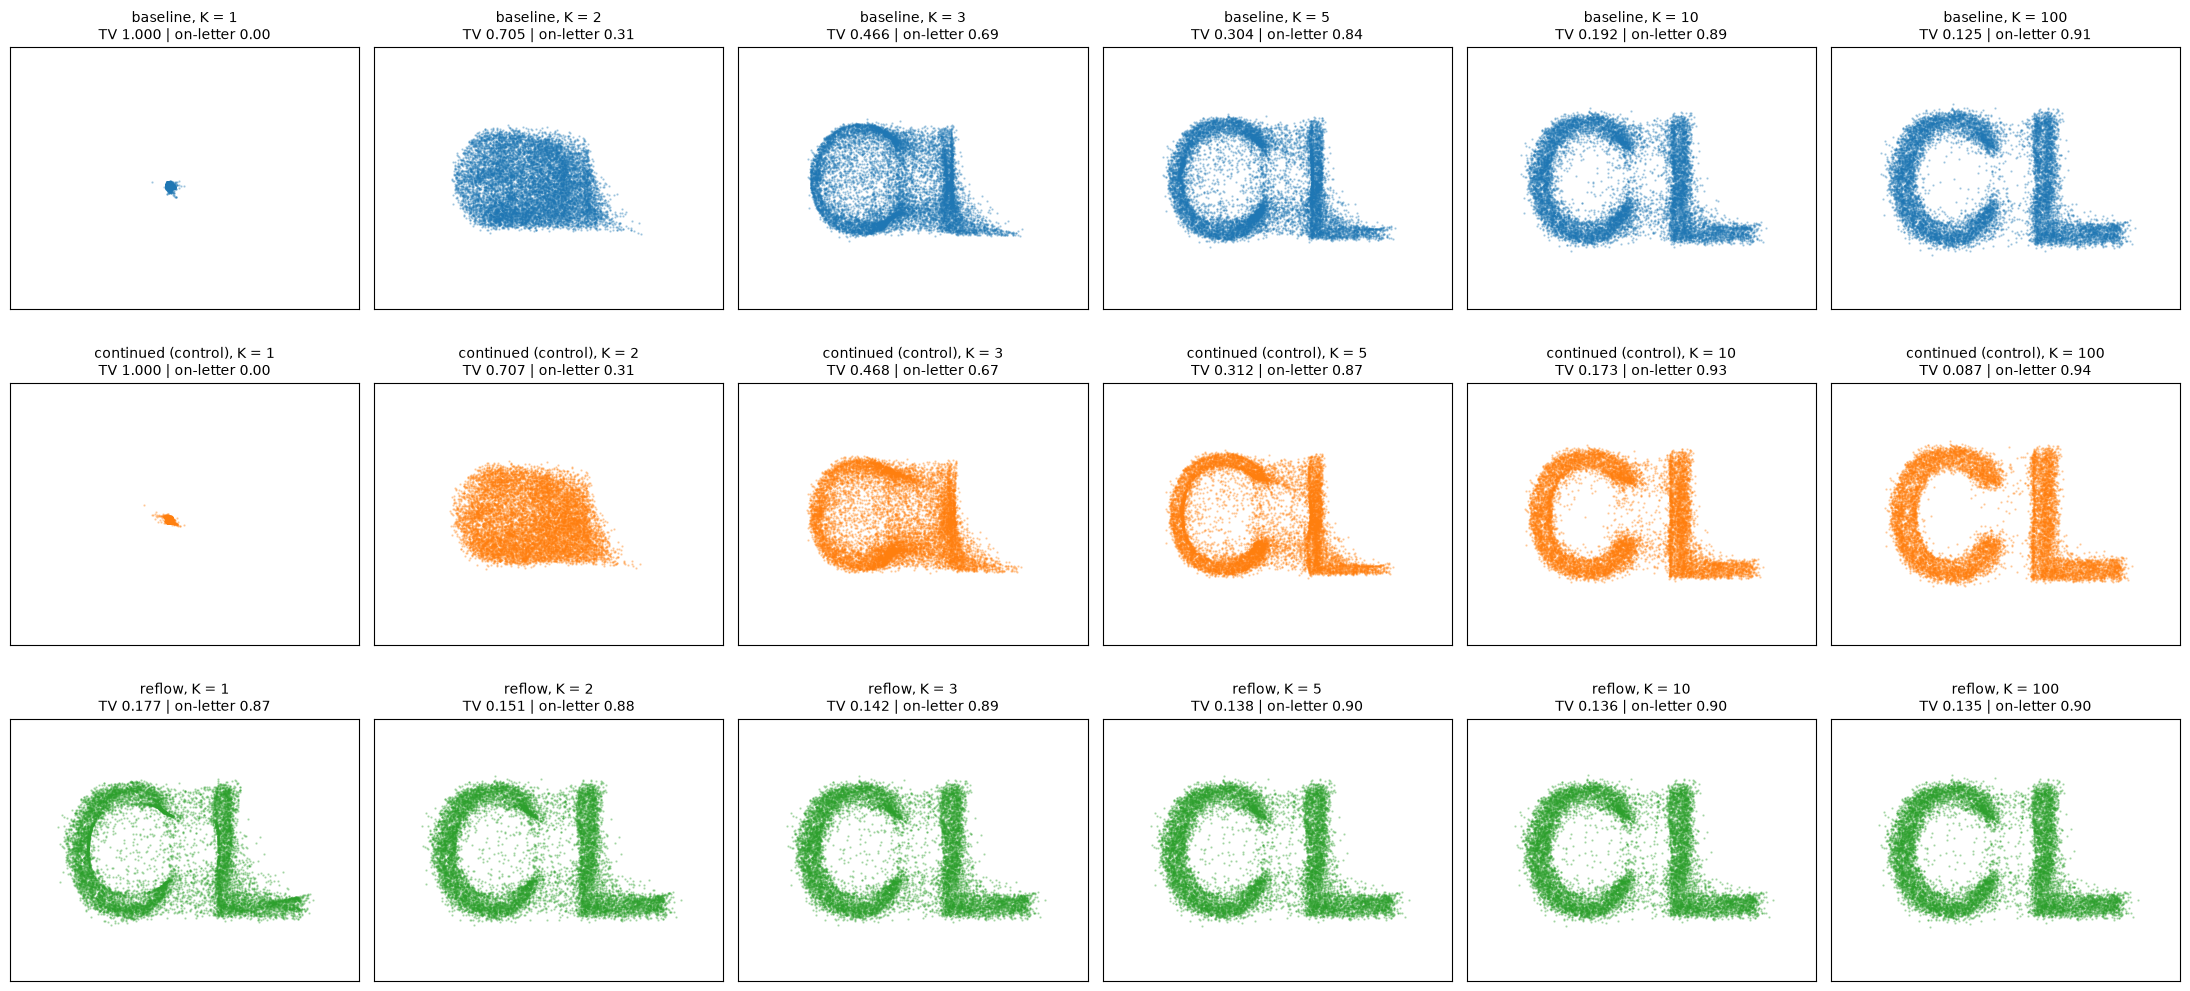

In [11]:
show_k = [1, 2, 3, 5, 10, 100]
fig, axes = plt.subplots(3, len(show_k), figsize=(22, 10.5))
for i, name in enumerate(MODELS):
    for j, k in enumerate(show_k):
        ax = axes[i, j]
        z = final_samples[(name, 0, k)]
        ax.scatter(*z[:12000].T, s=0.4, alpha=0.35, color=colors[name])
        r = eval_df[(eval_df.model == name) & (eval_df.seed == 0) & (eval_df.steps == k)].iloc[0]
        ax.set_title(f"{name}, K = {k}\nTV {r.TV_to_target:.3f} | on-letter {r.on_letter:.2f}", fontsize=10)
        ax.set(xlim=(-4, 4), ylim=(-3, 3), aspect="equal")
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(OUT / "task2_samples_grid_seed0.png", dpi=110, bbox_inches="tight")
plt.show()

### Path straightness

Excess length (path length minus start-to-end distance) and velocity deviation, both measured on a common 200-step grid.

In [12]:
@torch.no_grad()
def straightness(model, z0, K=K_STRAIGHT):
    z, path = euler_sample(model, z0, K, return_path=True)
    steps = path[1:] - path[:-1]                          # (K, N, 2) = dt * v
    length = steps.norm(dim=2).sum(0)
    chord_vec = path[-1] - path[0]
    chord = chord_vec.norm(dim=1)
    vel_dev = ((steps * K - chord_vec) ** 2).sum(2).mean(0)
    return {"excess_length": (length - chord).mean().item(),
            "length_over_chord": (length / chord.clamp_min(1e-6)).mean().item(),
            "velocity_deviation": vel_dev.mean().item(),
            "frac_paths_over_5pct_longer": ((length / chord.clamp_min(1e-6)) > 1.05).float().mean().item()}, path


z0_s = z0_eval[:N_STRAIGHT]
st_rows, paths_seed0 = [], {}
for name, models in MODELS.items():
    for seed in SEEDS:
        m, path = straightness(models[seed], z0_s)
        st_rows.append({"model": name, "seed": seed, **m})
        if seed == 0:
            paths_seed0[name] = path
st_df = pd.DataFrame(st_rows)
st_df.to_csv(OUT / "task2_straightness.csv", index=False)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(st_df.groupby("model")[["excess_length", "length_over_chord", "velocity_deviation",
                                     "frac_paths_over_5pct_longer"]].agg(["mean", "std"]))

excess_length        length_over_chord         \
                             mean    std              mean    std   
model                                                               
baseline                   0.4218 0.0032            2.0282 0.0386   
continued (control)        0.4238 0.0041            2.0040 0.0643   
reflow                     0.0001 0.0000            1.0009 0.0004   

                    velocity_deviation        frac_paths_over_5pct_longer  \
                                  mean    std                        mean   
model                                                                       
baseline                        1.1003 0.0099                      0.9794   
continued (control)             1.1120 0.0029                      0.9812   
reflow                          0.0003 0.0000                      0.0011   

                            
                       std  
model                       
baseline            0.0011  
continued (control) 0.0012  
reflow              0.0003

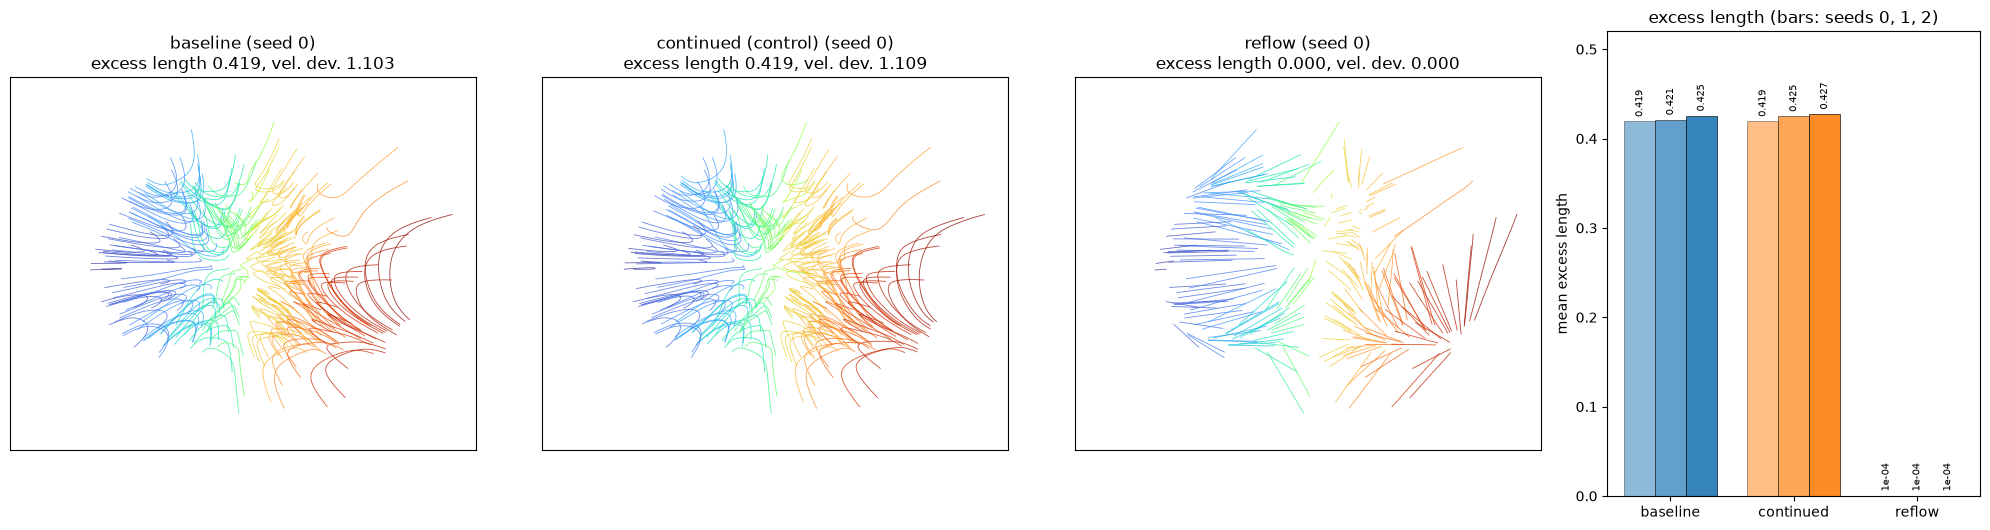

In [13]:
fig = plt.figure(figsize=(20, 5.4))
gs = fig.add_gridspec(1, 4, width_ratios=[1, 1, 1, 0.8])
n_show = 250
end_c = plt.get_cmap("turbo")(np.clip((paths_seed0["baseline"][-1, :n_show, 0].numpy() + 3) / 6, 0, 1))
for j, name in enumerate(MODELS):
    ax = fig.add_subplot(gs[j])
    p = paths_seed0[name][:, :n_show].numpy()
    for i in range(n_show):
        ax.plot(p[:, i, 0], p[:, i, 1], color=end_c[i], lw=0.6, alpha=0.8)
    m = st_df[(st_df.model == name) & (st_df.seed == 0)].iloc[0]
    ax.set_title(f"{name} (seed 0)\nexcess length {m.excess_length:.3f}, vel. dev. {m.velocity_deviation:.3f}")
    ax.set(xlim=(-4, 4), ylim=(-3.2, 3.2), aspect="equal")
    ax.set_xticks([]); ax.set_yticks([])
ax = fig.add_subplot(gs[3])
x = np.arange(len(MODELS))
for s_i, seed in enumerate(SEEDS):
    vals = [st_df[(st_df.model == n) & (st_df.seed == seed)].excess_length.iloc[0] for n in MODELS]
    bars = ax.bar(x + (s_i - 1) * 0.25, vals, width=0.25, color=[colors[n] for n in MODELS],
                  alpha=0.5 + 0.2 * s_i, edgecolor="k", lw=0.5)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}" if v >= 0.001 else f"{v:.0e}",
                ha="center", va="bottom", fontsize=7, rotation=90)
ax.set_xticks(x, ["baseline", "continued", "reflow"])
ax.set(ylabel="mean excess length", ylim=(0, 0.52), title="excess length (bars: seeds 0, 1, 2)")
plt.tight_layout()
plt.savefig(OUT / "task2_trajectories_and_straightness.png", dpi=120, bbox_inches="tight")
plt.show()

### Inheritance check

Is each model closer to the true target or to its teacher's distribution?

In [14]:
inh = eval_df[eval_df.steps == 100].groupby("model")[["TV_to_target", "TV_to_teacher200"]].agg(["mean", "std"])
with pd.option_context("display.float_format", "{:.4f}".format):
    display(inh)

# same-start comparison: how far does each model's endpoint land from the teacher's endpoint for the SAME z0?
# (legitimate point-wise comparison: both are deterministic maps of the same starting point)
for name, models in MODELS.items():
    d = [(euler_sample(models[s], z0_s, 100) - teacher[s][:N_STRAIGHT]).norm(dim=1).mean().item() for s in SEEDS]
    print(f"{name:22s} mean |endpoint - teacher endpoint| (same z0, 100 steps): "
          f"{np.mean(d):.4f} (seeds: {', '.join(f'{v:.4f}' for v in d)})")

TV_to_target        TV_to_teacher200       
                            mean    std             mean    std
model                                                          
baseline                  0.1315 0.0057           0.0121 0.0001
continued (control)       0.0884 0.0016           0.0776 0.0042
reflow                    0.1403 0.0053           0.0271 0.0017

baseline               mean |endpoint - teacher endpoint| (same z0, 100 steps): 0.0074 (seeds: 0.0074, 0.0073, 0.0074)
continued (control)    mean |endpoint - teacher endpoint| (same z0, 100 steps): 0.0435 (seeds: 0.0442, 0.0368, 0.0496)
reflow                 mean |endpoint - teacher endpoint| (same z0, 100 steps): 0.0099 (seeds: 0.0106, 0.0094, 0.0098)


In [15]:
def tv_at(model_name, k):
    v = eval_df[(eval_df.model == model_name) & (eval_df.steps == k)].TV_to_target
    return round(v.mean(), 4), round(v.std(), 4)


st_mean = st_df.groupby("model").mean(numeric_only=True)
key = {
    "noise_floor_TV": round(noise_floor, 4),
    "TV_mean_std": {m: {k: tv_at(m, k) for k in STEP_COUNTS} for m in MODELS},
    "excess_length": st_mean.excess_length.round(5).to_dict(),
    "velocity_deviation": st_mean.velocity_deviation.round(5).to_dict(),
    "reflow_worse_than_own_baseline_at_K100_per_seed": [bool(
        eval_df[(eval_df.model == "reflow") & (eval_df.steps == 100) & (eval_df.seed == s)].TV_to_target.iloc[0] >
        eval_df[(eval_df.model == "baseline") & (eval_df.steps == 100) & (eval_df.seed == s)].TV_to_target.iloc[0])
        for s in SEEDS],
    "mean_costs_s": cost_df.loc["mean"].drop("seed").round(2).to_dict(),
}
(OUT / "key_results.json").write_text(json.dumps(key, indent=2))
key

{'noise_floor_TV': np.float64(0.0416),
 'TV_mean_std': {'baseline': {1: (np.float64(0.9996), np.float64(0.0004)),
   2: (np.float64(0.7121), np.float64(0.0065)),
   3: (np.float64(0.4711), np.float64(0.005)),
   5: (np.float64(0.3099), np.float64(0.0051)),
   10: (np.float64(0.2006), np.float64(0.0079)),
   25: (np.float64(0.1478), np.float64(0.0083)),
   50: (np.float64(0.136), np.float64(0.0071)),
   100: (np.float64(0.1315), np.float64(0.0057))},
  'continued (control)': {1: (np.float64(0.9998), np.float64(0.0004)),
   2: (np.float64(0.712), np.float64(0.0061)),
   3: (np.float64(0.4684), np.float64(0.0009)),
   5: (np.float64(0.3128), np.float64(0.0018)),
   10: (np.float64(0.1736), np.float64(0.0011)),
   25: (np.float64(0.1096), np.float64(0.0019)),
   50: (np.float64(0.0947), np.float64(0.0018)),
   100: (np.float64(0.0884), np.float64(0.0016))},
  'reflow': {1: (np.float64(0.1778), np.float64(0.0065)),
   2: (np.float64(0.156), np.float64(0.0061)),
   3: (np.float64(0.1478), np

## Task 3 — What the evidence supports

Reflow made paths almost perfectly straight and gave good samples in 1–3 steps, but it copied its teacher's errors, and longer baseline training gave the best many-step quality (see the report for the full analysis).